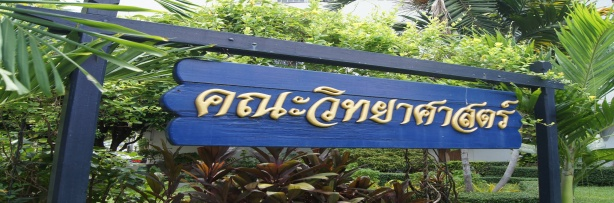

### <span style='color:lightgreen;'>Inter-Mean Repeat Algorithm สำหรับ Adaptive Thresholding</span>

บทนี้เป็นตัวอย่างการหา threshold จาก histogram ด้วย **Inter-Mean Algorithm** แบบวนซ้ำ
แนวคิดหลักคือแบ่ง pixel เป็น 2 กลุ่ม คำนวณค่าเฉลี่ยของแต่ละกลุ่ม แล้วใช้ค่าเฉลี่ยทั้งสองมาสร้าง threshold ใหม่

ในเวอร์ชัน Repeat เราจะนำ threshold ที่ได้ไปปรับช่วง histogram แล้วคำนวณซ้ำอีกครั้ง จึงมองเป็น adaptive thresholding แบบง่ายได้


#### <span style='color:lightblue;'>Workflow ของบทเรียน</span>

1. เตรียม library และฟังก์ชันสั้น ๆ ที่ใช้ซ้ำ
2. อ่านภาพ grayscale และแสดงภาพ
3. สร้าง histogram
4. หา threshold ด้วย Inter-Mean จนค่า converge
5. ทำ Repeat โดยปรับช่วง histogram จาก threshold รอบก่อนหน้า
6. สร้าง binary image จาก threshold สุดท้าย


1. **<span style='color:lightgreen;'>Import Libraries</span>**

ใช้เฉพาะ library ที่จำเป็น เพื่อให้ code อ่านง่ายและไม่ซับซ้อน


In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (6, 4)


2. **<span style='color:lightgreen;'>Helper Functions</span>**

ฟังก์ชันใน cell นี้แบ่งเป็น 4 งาน: แสดงภาพ, สร้าง histogram, หา threshold และแปลงเป็นภาพ binary


In [ ]:
def show_img(img, title="Image"):
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")
    plt.show()


def hist_gray(img):
    return np.bincount(img.ravel(), minlength=256)


def plot_hist(hist, T=None, start=0, end=256, title="Histogram"):
    levels = np.arange(256)

    plt.figure(figsize=(7, 3))
    plt.plot(levels[start:end], hist[start:end], color="black")

    if T is not None:
        plt.axvline(T, color="red", linestyle="--", label=f"T = {T}")
        plt.legend()

    plt.title(title)
    plt.xlabel("Pixel intensity")
    plt.ylabel("Number of pixels")
    plt.grid(alpha=0.2)
    plt.show()


def next_threshold(hist, T, start=0, end=256):
    levels = np.arange(256)
    T = int(np.clip(round(T), start, end - 1))

    low_hist = hist[start:T + 1]
    high_hist = hist[T + 1:end]

    low_count = low_hist.sum()
    high_count = high_hist.sum()

    if low_count == 0 or high_count == 0:
        return T

    low_mean = np.dot(levels[start:T + 1], low_hist) / low_count #find มิว of h0
    high_mean = np.dot(levels[T + 1:end], high_hist) / high_count #find มิว of h1

    return int(round((low_mean + high_mean) / 2)) # should to return dict low_hist,high_hist, low_count, high_count 


def intermean(hist, start=0, end=256, T0=None, max_iter=50):
    levels = np.arange(256) # create array [0,1,2......,255]
    part = hist[start:end]

    if part.sum() == 0:
        return start, [start]

    if T0 is None:
        T0 = np.dot(levels[start:end], part) / part.sum() # find average with use round int(round(np.dot((levels[start:end], part) / part.sum()))) 

    history = [int(round(T0))]

    for _ in range(max_iter):
        T1 = next_threshold(hist, history[-1], start, end) #history[-1] use last index 
        history.append(T1)

        if T1 == history[-2]:
            break

    return history[-1], history


def repeat_intermean(hist, rounds=3, side="bright"): # เรียก intermean 3 ครั้งเพื่อทำการหา Threashold ใหม่ ทั้ง 3
    start, end = 0, 256
    steps = []

    for round_id in range(1, rounds + 1):
        if end - start <= 1:
            break

        T, history = intermean(hist, start=start, end=end)  
        steps.append((round_id, start, end, T, history))

        if side == "bright":
            start = T + 1
        else:
            end = T + 1

    return steps


def to_binary(img, T):
    out = np.zeros_like(img, dtype=np.uint8)
    out[img > T] = 255 # np.array and int if index == true จะมีค่า =255
    return out


3. **<span style='color:lightgreen;'>Read an Image</span>**

ตัวอย่างนี้ใช้ภาพ `gray2.png` เหมือน notebook เดิม ถ้าไม่พบไฟล์ จะสร้างภาพทดลองให้รันบทเรียนต่อได้


In [3]:
def demo_img(size=256):
    y, x = np.indices((size, size))
    img = np.tile(np.linspace(40, 210, size), (size, 1))

    cv2.rectangle(img, (45, 55), (175, 205), 95, thickness=-1)
    cv2.circle(img, (170, 110), 42, 230, thickness=-1)

    noise = np.random.default_rng(7).normal(0, 6, img.shape)
    return np.clip(img + noise, 0, 255).astype(np.uint8)


img_path = Path("./images/gray2.png")
img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)

if img is None:
    print(f"Image file not found: {img_path}")
    img = demo_img()
else:
    print(f"Image loaded from: {img_path}")

print(f"Image shape: {img.shape}")
print(f"Minimum intensity: {img.min()}")
print(f"Maximum intensity: {img.max()}")


Image loaded from: images\gray2.png
Image shape: (512, 512)
Minimum intensity: 92
Maximum intensity: 255


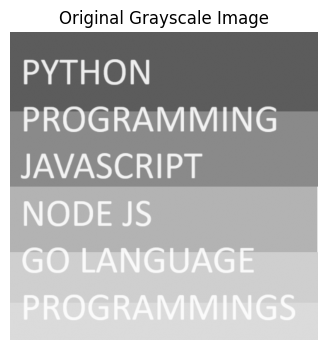

In [4]:
show_img(img, "Original Grayscale Image")


4. **<span style='color:lightgreen;'>Calculate and Plot Histogram</span>**

Histogram แสดงจำนวน pixel ในแต่ละระดับความเข้มตั้งแต่ 0 ถึง 255


Total pixels from histogram: 262,144
Total pixels from image: 262,144


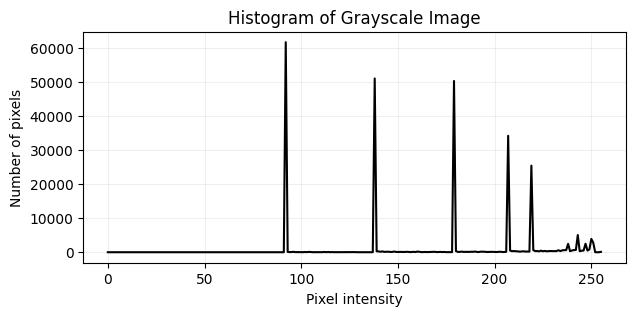

In [5]:
hist = hist_gray(img)

print(f"Total pixels from histogram: {hist.sum():,}")
print(f"Total pixels from image: {img.size:,}")

plot_hist(hist, title="Histogram of Grayscale Image")


5. **<span style='color:lightgreen;'>Inter-Mean หนึ่งชุดจน Converge</span>**

เริ่มจากค่าเฉลี่ยของภาพ แล้วปรับ threshold ซ้ำจนค่ารอบใหม่เท่ากับค่ารอบก่อนหน้า


Threshold history: [165, 160, 160]
Final threshold: 160
Number of updates: 2


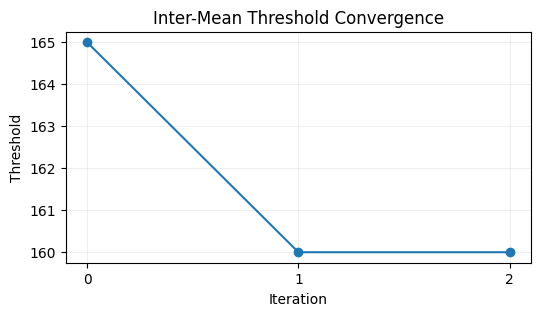

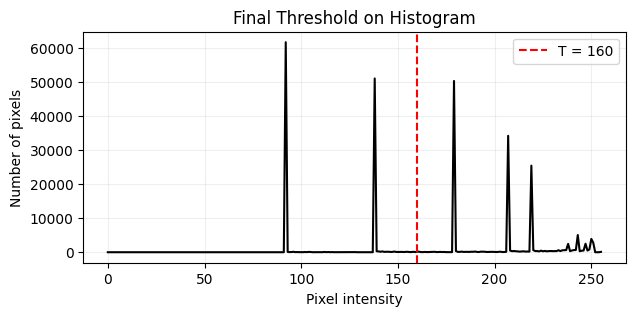

In [6]:
T, history = intermean(hist)

print("Threshold history:", history)
print(f"Final threshold: {T}")
print(f"Number of updates: {len(history) - 1}")

plt.figure(figsize=(6, 3))
plt.plot(range(len(history)), history, marker="o")
plt.title("Inter-Mean Threshold Convergence")
plt.xlabel("Iteration")
plt.ylabel("Threshold")
plt.xticks(range(len(history)))
plt.grid(alpha=0.2)
plt.show()

plot_hist(hist, T=T, title="Final Threshold on Histogram")


6. **<span style='color:lightgreen;'>Repeat Concept: Adaptive Thresholding แบบง่าย</span>**

หลังจากได้ threshold รอบแรก เราเลือกช่วง histogram ด้านที่สนใจ แล้วหา threshold ใหม่ในช่วงนั้น
ตัวอย่างนี้เลือกด้านสว่าง (`side = "bright"`) จึงขยับ `start` ไปหลัง threshold รอบก่อนหน้า


In [7]:
rounds = 3
side = "bright"
steps = repeat_intermean(hist, rounds=rounds, side=side)

for round_id, start, end, T, history in steps:
    print(f"Round {round_id}: range {start}-{end - 1}, T = {T}, history = {history}")

repeat_T = steps[-1][3]
print(f"Final repeat threshold: {repeat_T}")


Round 1: range 0-255, T = 160, history = [165, 160, 160]
Round 2: range 161-255, T = 200, history = [206, 200, 200]
Round 3: range 201-255, T = 228, history = [221, 227, 228, 228]
Final repeat threshold: 228


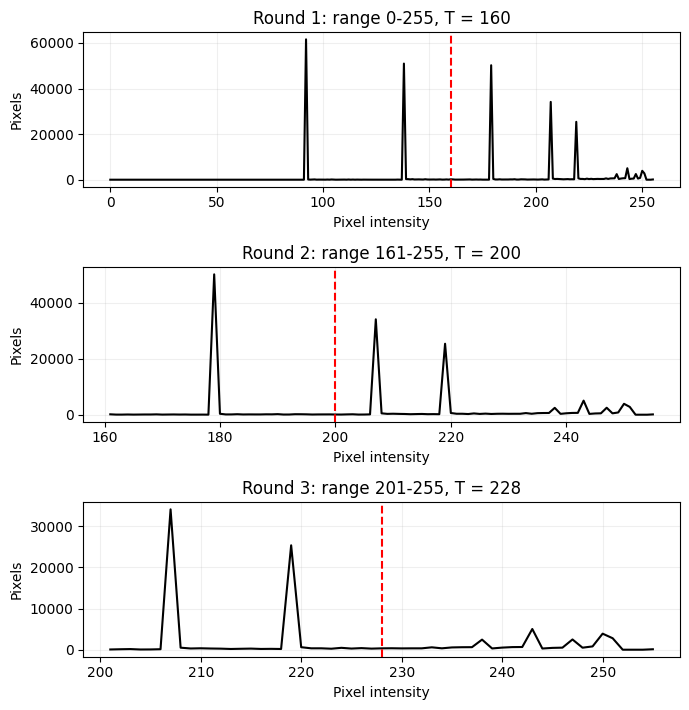

In [8]:
fig, axes = plt.subplots(len(steps), 1, figsize=(7, 2.4 * len(steps)))

if len(steps) == 1:
    axes = [axes]

for ax, (round_id, start, end, T, history) in zip(axes, steps):
    levels = np.arange(256)
    ax.plot(levels[start:end], hist[start:end], color="black")
    ax.axvline(T, color="red", linestyle="--")
    ax.set_title(f"Round {round_id}: range {start}-{end - 1}, T = {T}")
    ax.set_xlabel("Pixel intensity")
    ax.set_ylabel("Pixels")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


7. **<span style='color:lightgreen;'>Apply Threshold เพื่อสร้าง Binary Image</span>**

นำ threshold สุดท้ายจาก Repeat ไปแยกภาพเป็นสีดำและสีขาว


Threshold used by OpenCV: 228.0
Manual result equals OpenCV: True


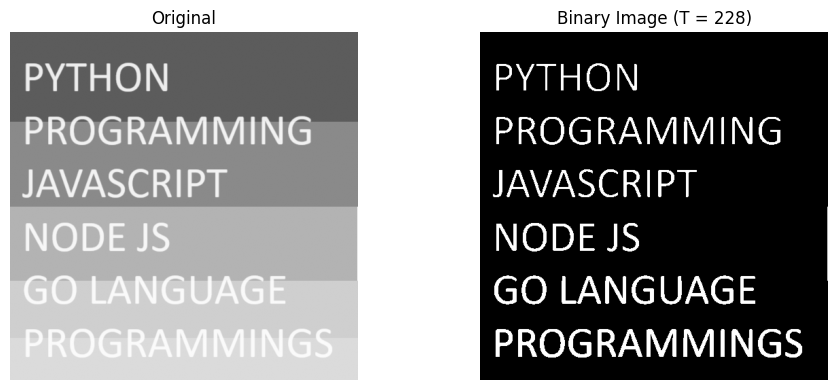

In [9]:
bin_img = to_binary(img, repeat_T)
ret, bin_cv = cv2.threshold(img, repeat_T, 255, cv2.THRESH_BINARY)

print(f"Threshold used by OpenCV: {ret}")
print("Manual result equals OpenCV:", np.array_equal(bin_img, bin_cv))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(bin_img, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Binary Image (T = {repeat_T})")
axes[1].axis("off")

plt.tight_layout()
plt.show()


8. **<span style='color:lightgreen;'>ทดลองเปลี่ยนด้านที่เลือก</span>**

ถ้าเลือก `dark` algorithm จะปรับช่วงไปทางระดับความเข้มต่ำ
ถ้าเลือก `bright` algorithm จะปรับช่วงไปทางระดับความเข้มสูง


In [10]:
for side in ["dark", "bright"]:
    steps = repeat_intermean(hist, rounds=3, side=side)
    thresholds = [step[3] for step in steps]
    print(f"{side:6s} side thresholds:", thresholds)


dark   side thresholds: [160, 115, 100]
bright side thresholds: [160, 200, 228]


#### <span style='color:Tomato;'>สรุปท้ายบท</span>

Inter-Mean Repeat เป็นการนำแนวคิด iterative thresholding มาใช้ซ้ำบนช่วง histogram ที่ปรับตามผลลัพธ์รอบก่อนหน้า
จุดสำคัญของบทนี้คือเข้าใจ 3 เรื่อง: histogram, ค่าเฉลี่ยของ pixel สองกลุ่ม และการวนซ้ำจน threshold คงที่

code เวอร์ชันนี้ตั้งใจให้สั้น ชื่อตัวแปรอ่านง่าย และแยกแต่ละขั้นตอนให้ทดลองแก้ไขได้สะดวก
